# DESCOBRINDO O FORMATO DOS DADOS: ASSIMETRIA E CURTOSE


## Situação de Aprendizagem — O Desafio do Analista Sênior

Chegamos à metade do nosso curso! Na **Data Organized**, você já aprendeu a encontrar o **meio** dos dados (Média e Mediana) e a medir se eles estão **espalhados** (Desvio Padrão).

Hoje, o Analista Sênior trouxe um novo problema:
"Duas lojas têm a mesma média de vendas, mas em uma delas quase todos os dias são parecidos e em outra existem alguns dias fora da curva que puxam os números para cima. Como eu descubro o **desenho** dessa fila de números sem precisar olhar linha por linha?"

É exatamente para isso que servem a **Assimetria** e a **Curtose**.

### Analogia do Dia a Dia: O Desenho de uma Montanha

Imagine que você empilhou todos os seus dados formando uma montanha de areia:

1. **Assimetria (*Skewness*) = Para qual lado a rampa escorrega?**
   - Se os dois lados da montanha descem iguais, ela é **Simétrica**.
   - Se existe uma rampa comprida esticada para o lado dos números **altos** (direita), ela é **Assimétrica Positiva**.
   - Se existe uma rampa comprida esticada para o lado dos números **baixos** (esquerda), ela é **Assimétrica Negativa**.

2. **Curtose (*Kurtosis*) = Qual é o formato do topo da montanha?**
   - **Mesocúrtica:** Um morro suave e equilibrado (parecido com um sino).
   - **Leptocúrtica:** Um pico fino e pontudo (quase todo mundo perto da média, mas com alguns valores muito distantes nas pontas).
   - **Platicúrtica:** Um morro baixo e achatado (os valores estão bem espalhados).

LInks: https://www.youtube.com/watch?v=BR9MAmi9zic

https://www.youtube.com/watch?v=CHuCoPgL1MA


https://www.youtube.com/watch?v=Oug4o3xmbJc

## Parte 1 (Nível Básico): Entendendo a Assimetria na Prática

A assimetria mede o grau de desvio da simetria de uma distribuição em relação à sua média. Ela indica se os dados estão mais concentrados de um lado do gráfico do que do outro.

### O que é?
É um número calculado pelo comando `.skew()` que mostra se a maioria dos seus dados está equilibrada ou se existem poucos valores muito altos (ou muito baixos) puxando a média.

### Para que serve?
Para você não ser enganado pela **Média**. Quando a assimetria é forte, a média deixa de representar a maioria das pessoas/vendas e a **Mediana** passa a ser a melhor escolha.

### Como ler o número do `.skew()` (Tabela de Tradução):
| Resultado do `.skew()` | O que significa? | O que acontece com a Média? |
| :--- | :--- | :--- |
| **Entre `-0.5` e `+0.5`** | **Simétrica** (Equilibrada) | A Média e a Mediana são praticamente iguais. |
| **Maior que `+0.5`** | **Assimétrica Positiva** (Puxada para cima) | Poucos valores muito **altos** puxam a Média para cima da Mediana. |
| **Menor que `-0.5`** | **Assimétrica Negativa** (Puxada para baixo) | Poucos valores muito **baixos** puxam a Média para baixo da Mediana. |

> *Curiosidade Matemática (Opcional):* Por baixo dos panos, o Python calcula $\frac{\sum (x_i - \mu)^3}{N \cdot \sigma^3}$. Elevamos ao cubo ($^3$) porque a potência ímpar mantém o sinal de positivo ($+$) ou negativo ($-$), revelando para qual lado a cauda está esticada.

In [ ]:
# Passo 1: Importa a biblioteca Pandas para trabalhar com tabelas e séries
import pandas as pd
import seaborn as sns

# Passo 2: Cria uma lista simples com os salários de 7 funcionários de uma pequena loja
# Observe que 6 funcionários ganham perto de R$ 2.000, mas o gerente ganha R$ 15.000
salarios = pd.Series([1800, 1900, 2000, 2000, 2100, 2200, 15000])

# Exibe a série criada
print("Salários da equipe:", salarios.tolist())

In [ ]:
import seaborn as sns

# Passo 3: Calcula a Média, a Mediana e a Assimetria (.skew()) dos salários
media_sal = salarios.mean()          # Soma tudo e divide por 7
mediana_sal = salarios.median()      # Pega o salário bem do meio da fila ordenada
assimetria_sal = salarios.skew()     # Mede para qual lado os dados estão puxados

# Mostra os resultados na tela
print(f"Média salarial:   R$ {media_sal:.2f}")
print(f"Mediana salarial: R$ {mediana_sal:.2f}")
print(f"Assimetria:       {assimetria_sal:.2f}")

sns.histplot(salarios, kde=True)
sns.despine() #desenha os eixos superior e direito do gráfico

*Leitura Analítica (Exemplo 1 — Salários):*

Olhe como os números contam a história: o salário típico da equipe é **R$ 2.000,00 (Mediana)**, mas o único salário alto do gerente (**R$ 15.000,00**) puxou a **Média para R$ 3.857,14**. O comando `.skew()` acusou **`+2.62`** (bem maior que `+0.5`), confirmando uma **Assimetria Positiva**. Se você dissesse que o funcionário comum ganha R$ 3.857, estaria passando uma informação distorcida!

## Parte 2 (Nível Básico-Intermediário): Comparando os 3 Cenários de Assimetria

In [ ]:
# Cria uma tabela com 3 cenários fáceis de comparar:
# 1. Equilibrado | 2. Puxado para cima (Positiva) | 3. Puxado para baixo (Negativa)
df_cenarios = pd.DataFrame({
    'Equilibrado': [10, 20, 30, 40, 50, 60, 70],
    'Puxado_Cima': [10, 12, 13, 14, 15, 16, 90],
    'Puxado_Baixo': [5, 84, 85, 86, 87, 88, 90]
})

# Analisa cada coluna automaticamente usando a nossa tabela de tradução
for coluna in df_cenarios.columns:
    serie = df_cenarios[coluna]                      # Pega uma coluna por vez
    valor_skew = serie.skew()                        # Calcula a assimetria
    
    # Traduz o número em texto simples
    if -0.5 <= valor_skew <= 0.5:
        diagnostico = "Simétrica (Equilibrada)"
    elif valor_skew > 0.5:
        diagnostico = "Assimétrica Positiva (Cauda à direita)"
    else:
        diagnostico = "Assimétrica Negativa (Cauda à esquerda)"
        
    print(f"{coluna:14s} | Média: {serie.mean():5.1f} | Mediana: {serie.median():5.1f} | Skew: {valor_skew:6.2f} -> {diagnostico}")

### Gráfico 1 — Distribuição equilibrada

In [ ]:
import matplotlib.pyplot as plt

serie = df_cenarios['Equilibrado']

media = serie.mean()
mediana = serie.median()
skew = serie.skew()

plt.figure(figsize=(8, 5))

plt.hist(serie, bins=7, edgecolor='black', alpha=0.75)

plt.axvline(media, linestyle='--', linewidth=2,
            label=f'Média = {media:.1f}')

plt.axvline(mediana, linestyle=':', linewidth=2,
            label=f'Mediana = {mediana:.1f}')

plt.title(f'Distribuição Equilibrada | Skew = {skew:.2f}')
plt.xlabel('Valores')
plt.ylabel('Frequência')
plt.legend()
plt.grid(axis='y', alpha=0.25)


plt.show()

### Gráfico 2 — Assimetria positiva (cauda à direita)

In [ ]:
serie = df_cenarios['Puxado_Cima']

media = serie.mean()
mediana = serie.median()
skew = serie.skew()

plt.figure(figsize=(8, 5))

plt.hist(serie, bins=7, edgecolor='black', alpha=0.75)

plt.axvline(media, linestyle='--', linewidth=2,
            label=f'Média = {media:.1f}')

plt.axvline(mediana, linestyle=':', linewidth=2,
            label=f'Mediana = {mediana:.1f}')

plt.title(f'Assimetria Positiva | Skew = {skew:.2f}')
plt.xlabel('Valores')
plt.ylabel('Frequência')
plt.legend()
plt.grid(axis='y', alpha=0.25)

plt.show()

### Gráfico 3 — Assimetria negativa (cauda à esquerda)

In [ ]:
serie = df_cenarios['Puxado_Baixo']

media = serie.mean()
mediana = serie.median()
skew = serie.skew()

plt.figure(figsize=(8, 5))

plt.hist(serie, bins=7, edgecolor='black', alpha=0.75)

plt.axvline(media, linestyle='--', linewidth=2,
            label=f'Média = {media:.1f}')

plt.axvline(mediana, linestyle=':', linewidth=2,
            label=f'Mediana = {mediana:.1f}')

plt.title(f'Assimetria Negativa | Skew = {skew:.2f}')
plt.xlabel('Valores')
plt.ylabel('Frequência')
plt.legend()
plt.grid(axis='y', alpha=0.25)

plt.show()

###  Bônus

In [ ]:

# ============================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

import pandas as pd                  # Manipulação e organização dos dados
import matplotlib.pyplot as plt      # Criação dos gráficos


# ============================================================
# 2. CRIAÇÃO DA TABELA COM OS TRÊS CENÁRIOS
# ============================================================

# Criamos um DataFrame com três conjuntos de dados:
#
# Equilibrado: apresenta uma distribuição simétrica.
# Puxado_Cima: apresenta assimetria positiva (cauda à direita).
# Puxado_Baixo: apresenta assimetria negativa (cauda à esquerda).

df_cenarios = pd.DataFrame({

    'Equilibrado': [10, 20, 30, 40, 50, 60, 70],

    'Puxado_Cima': [10, 12, 13, 14, 15, 16, 90],

    'Puxado_Baixo': [5, 84, 85, 86, 87, 88, 90]

})


# ============================================================
# 3. ANÁLISE AUTOMÁTICA DE CADA CENÁRIO
# ============================================================

# O comando for percorre cada coluna da tabela.
# Assim, não precisamos analisar os três cenários manualmente.

for coluna in df_cenarios.columns:

    # Seleciona os valores da coluna atual.
    serie = df_cenarios[coluna]

    # Calcula a média aritmética.
    media = serie.mean()

    # Calcula a mediana.
    # A mediana representa o valor central dos dados ordenados.
    mediana = serie.median()

    # Calcula o coeficiente de assimetria (Skewness).
    # Valores próximos de zero indicam simetria.
    # Valores positivos indicam cauda à direita.
    # Valores negativos indicam cauda à esquerda.
    skew = serie.skew()


    # ========================================================
    # 4. CLASSIFICAÇÃO DA ASSIMETRIA
    # ========================================================

    # Se o coeficiente estiver entre -0.5 e +0.5,
    # classificamos a distribuição como aproximadamente simétrica.

    if -0.5 <= skew <= 0.5:

        diagnostico = "Simétrica (Equilibrada)"

    # Se o coeficiente for maior que +0.5,
    # classificamos como assimetria positiva.

    elif skew > 0.5:

        diagnostico = "Assimétrica Positiva (Cauda à direita)"

    # Se o coeficiente for menor que -0.5,
    # classificamos como assimetria negativa.

    else:

        diagnostico = "Assimétrica Negativa (Cauda à esquerda)"


    # Exibe os resultados estatísticos no terminal.
    # :.1f apresenta uma casa decimal.
    # :.2f apresenta duas casas decimais.

    print(
        f"{coluna:14s} | "
        f"Média: {media:5.1f} | "
        f"Mediana: {mediana:5.1f} | "
        f"Skew: {skew:6.2f} -> {diagnostico}"
    )


# ============================================================
# 5. CRIAÇÃO DOS GRÁFICOS
# ============================================================

# Percorremos novamente as três colunas para criar
# um gráfico independente para cada cenário.

for coluna in df_cenarios.columns:

    # Seleciona os dados do cenário atual.
    serie = df_cenarios[coluna]

    # Calcula as estatísticas necessárias para o gráfico.
    media = serie.mean()
    mediana = serie.median()
    skew = serie.skew()


    # ========================================================
    # 6. CONFIGURAÇÃO DA FIGURA
    # ========================================================

    # Cria uma figura com 8 polegadas de largura
    # e 5 polegadas de altura.
    #
    # O ax representa a área onde desenharemos o gráfico.

    fig, ax = plt.subplots(figsize=(8, 5))


    # ========================================================
    # 7. CONSTRUÇÃO DO HISTOGRAMA
    # ========================================================

    # O histograma mostra a frequência dos valores.
    #
    # bins=7 divide os dados em sete intervalos.
    # edgecolor='black' adiciona bordas às barras.
    # alpha=0.75 controla a transparência.

    frequencias, bins, _ = ax.hist(
        serie,
        bins=7,
        edgecolor='black',
        alpha=0.75
    )


    # ========================================================
    # 8. INSERÇÃO DA LINHA DA MÉDIA
    # ========================================================

    # ax.axvline cria uma linha vertical na posição da média.
    #
    # linestyle='--' define a linha tracejada.
    # linewidth=2 define sua espessura.
    # label cria a identificação na legenda.

    ax.axvline(
        media,
        linestyle='--',
        linewidth=2,
        label=f'Média = {media:.1f}'
    )


    # ========================================================
    # 9. INSERÇÃO DA LINHA DA MEDIANA
    # ========================================================

    # Cria uma linha vertical na posição da mediana.
    #
    # linestyle=':' representa uma linha pontilhada.

    ax.axvline(
        mediana,
        linestyle=':',
        linewidth=2,
        label=f'Mediana = {mediana:.1f}'
    )


    # ========================================================
    # 10. DEFINIÇÃO DA ALTURA DA SETA
    # ========================================================

    # max(frequencias) identifica a maior frequência
    # encontrada no histograma.
    #
    # Multiplicamos por 1.15 para posicionar a seta
    # um pouco acima das barras.

    y = max(frequencias) * 1.15


    # ========================================================
    # 11. IDENTIFICAÇÃO DA DIREÇÃO DA ASSIMETRIA
    # ========================================================

    # CASO 1: ASSIMETRIA POSITIVA
    #
    # Quando o Skew é maior que +0.5,
    # a cauda da distribuição está voltada para a direita.

    if skew > 0.5:

        ax.annotate(

            # Texto que aparecerá no gráfico.
            'Assimetria positiva →',

            # Coordenada onde a seta termina.
            # serie.max() indica o maior valor observado.
            xy=(serie.max(), y),

            # Coordenada onde o texto começa.
            # Utilizamos a mediana como referência.
            xytext=(mediana, y),

            # Configura a aparência da seta.
            arrowprops=dict(
                arrowstyle='->',
                linewidth=2
            ),

            # Centraliza o texto horizontalmente.
            ha='center',

            # Posiciona o texto acima da linha da seta.
            va='bottom'
        )


    # CASO 2: ASSIMETRIA NEGATIVA
    #
    # Quando o Skew é menor que -0.5,
    # a cauda da distribuição está voltada para a esquerda.

    elif skew < -0.5:

        ax.annotate(

            # Texto que aparecerá no gráfico.
            '← Assimetria negativa',

            # Coordenada onde a seta termina.
            # serie.min() indica o menor valor observado.
            xy=(serie.min(), y),

            # Coordenada onde o texto começa.
            xytext=(mediana, y),

            # Configura a aparência da seta.
            arrowprops=dict(
                arrowstyle='->',
                linewidth=2
            ),

            # Centraliza o texto horizontalmente.
            ha='center',

            # Posiciona o texto acima da linha da seta.
            va='bottom'
        )


    # CASO 3: DISTRIBUIÇÃO SIMÉTRICA
    #
    # Quando o Skew está entre -0.5 e +0.5,
    # não indicamos uma direção predominante da cauda.

    else:

        # Insere um texto acima da posição da média.
        ax.text(
            media,
            y,
            'Distribuição simétrica',
            ha='center',
            va='bottom'
        )


    # ========================================================
    # 12. CONFIGURAÇÃO DOS TÍTULOS E EIXOS
    # ========================================================

    # O título apresenta o nome do cenário e seu coeficiente.
    ax.set_title(f'{coluna} | Skew = {skew:.2f}')

    # Nome do eixo horizontal.
    ax.set_xlabel('Valores')

    # Nome do eixo vertical.
    ax.set_ylabel('Frequência')


    # ========================================================
    # 13. AJUSTE DA ESCALA VERTICAL
    # ========================================================

    # Aumentamos o limite superior do eixo Y para garantir
    # espaço suficiente para visualizar a seta e o texto.

    ax.set_ylim(0, y * 1.25)


    # ========================================================
    # 14. FINALIZAÇÃO DO GRÁFICO
    # ========================================================

    # Exibe a legenda com média e mediana.
    ax.legend()

    # Adiciona linhas horizontais auxiliares.
    # alpha controla a transparência da grade.
    ax.grid(axis='y', alpha=0.25)

    # Ajusta automaticamente os espaços do gráfico.
    plt.tight_layout()

    # Exibe o gráfico na tela.
    plt.show()


*Leitura Analítica (Exemplo 2 — Os 3 Cenários):*
- Na coluna `Equilibrado`, a Média (`40.0`) e a Mediana (`40.0`) são idênticas e o `Skew` é `0.00`.
- Na coluna `Puxado_Cima`, o valor `90` puxou a Média (`24.3`) para cima da Mediana (`14.0`) $\rightarrow$ `Skew = +2.60`.
- Na coluna `Puxado_Baixo`, o valor `5` puxou a Média (`75.0`) para baixo da Mediana (`86.0`) $\rightarrow$ `Skew = -2.62`.

*Dica:* As linhas tracejadas representam a média (--) e a mediana (:). A distância entre elas ajuda a visualizar o efeito da assimetria.

## Parte 3 (Nível Intermediário): Entendendo a Curtose (*Kurtosis*)

A curtose mede o grau de achatamento ou a concentração de dados nas caudas da distribuição, indicando a presença de valores extremos (outliers).

### O que é?
É a medida que diz se os dados estão **muito concentrados no meio** (formando um pico fino) ou **bem espalhados** (formando uma curva achatada).

### Para que serve?
Para prever o **risco de acontecerem valores extremos (*outliers*)**. Quanto mais pontuda for a curva, maior a chance de aparecerem casos muito fora do padrão.

### Atenção a um detalhe do Pandas (`+ 3`):
Normalmente a curva normal equilibrada vale **`3.0`**. Porém, o Python (`.kurtosis()`) subtrai 3 automaticamente na conta interna (deixando a normal valendo `0`). Para ler o resultado exatamente como está na nossa tabela do curso, basta somar **`+ 3`** no final: `serie.kurtosis() + 3`.

### Como ler o número da Curtose (`serie.kurtosis() + 3`):
| Resultado (`kurtosis() + 3`) | Nome Técnico | O que significa na prática? |
| :--- | :--- | :--- |
| **Entre `2.5` e `3.5`** | **Mesocúrtica** | Curva normal equilibrada. Poucos *outliers*. |
| **Menor que `2.5`** | **Platicúrtica** | Curva achatada (dados espalhados). *Outliers* são comuns. |
| **Maior que `3.5`** | **Leptocúrtica** | Pico fino e alto (muito concentrado no meio, mas com pontas longas). *Outliers* são **muito comuns**. |

In [ ]:
# Importa NumPy e bibliotecas de gráficos (Matplotlib e Seaborn)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Fixa a semente aleatória para os números serem sempre os mesmos na aula
np.random.seed(42)

# Cria dois grupos de 500 entregas:
# Grupo A: Entregas normais equilibradas (Mesocúrtica)
entregas_normais = pd.Series(np.random.normal(loc=30, scale=5, size=500))

# Grupo B: Quase todas as entregas em 30 min, mas com alguns atrasos gigantes (Leptocúrtica)
entregas_pico = pd.Series(np.random.laplace(loc=30, scale=2, size=500))

# Calcula a Curtose na escala do curso (+ 3)
kurt_a = entregas_normais.kurtosis() + 3
kurt_b = entregas_pico.kurtosis() + 3

print(f"Grupo A (Normal) -> Curtose: {kurt_a:.2f} (Entre 2.5 e 3.5 -> Mesocúrtica)")
print(f"Grupo B (Pico)   -> Curtose: {kurt_b:.2f} (Maior que 3.5 -> Leptocúrtica)")

In [ ]:
# Desenha os dois gráficos lado a lado para enxergar a diferença visual do topo
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico da esquerda: Curva Mesocúrtica (topo suave)
sns.histplot(entregas_normais, bins=25, kde=True, color='#3182bd', ax=axes[0])
axes[0].set_title(f'Topo Suave — Mesocúrtica ({kurt_a:.2f})', fontweight='bold')
axes[0].set_xlabel('Minutos')

# Gráfico da direita: Curva Leptocúrtica (topo fino e pontudo)
sns.histplot(entregas_pico, bins=25, kde=True, color='#de2d26', ax=axes[1])
axes[1].set_title(f'Topo Fino — Leptocúrtica ({kurt_b:.2f})', fontweight='bold')
axes[1].set_xlabel('Minutos')

plt.tight_layout()
plt.show()

*Leitura Analítica (Visualizando a Curtose):*

Veja no gráfico da direita (vermelho) como a curva **Leptocúrtica (`7.16`)** sobe bem alto e fina no meio (perto de 30 minutos), mas estica pontas compridas para os dois lados (indo abaixo de 15 e acima de 45 minutos). Isso avisa ao gestor que eventos extremos acontecem com muito mais frequência nessa operação.

Mesocúrtica    | Curtose:  3.27 | Diagnóstico: Mesocúrtica
Platicúrtica   | Curtose:  1.74 | Diagnóstico: Platicúrtica
Leptocúrtica   | Curtose:  5.11 | Diagnóstico: Leptocúrtica


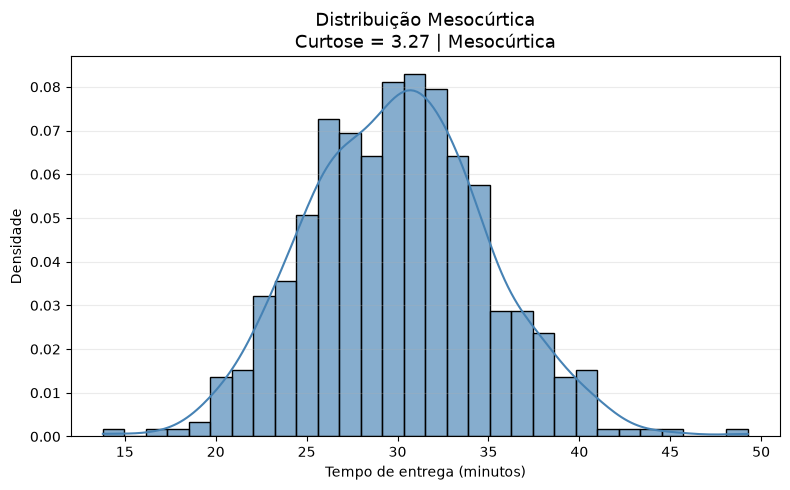

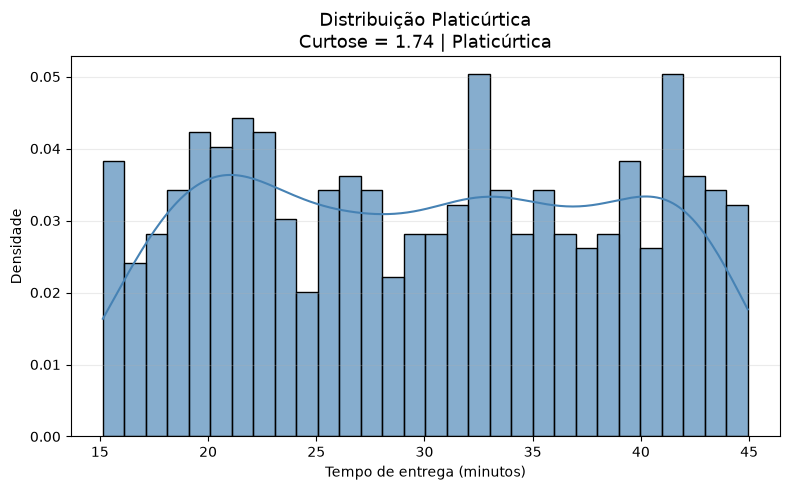

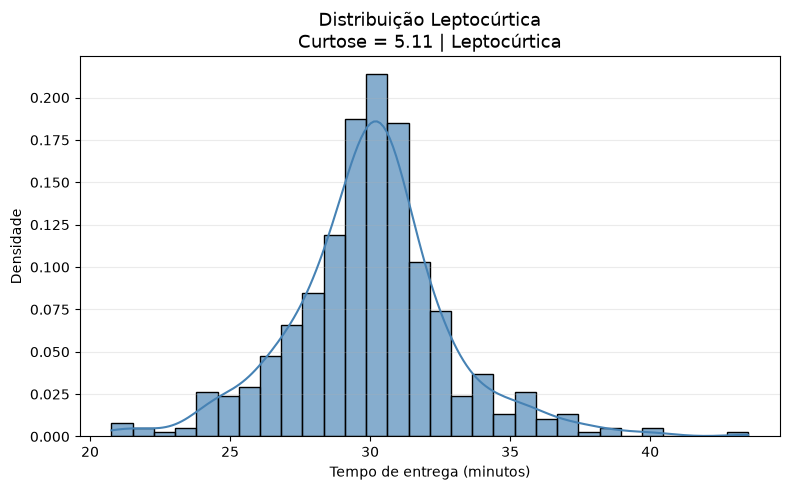

In [27]:

# ============================================================
# 1. IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

# NumPy: geração de números aleatórios.
import numpy as np

# Pandas: organização dos dados e cálculo da curtose.
import pandas as pd

# Matplotlib: construção dos gráficos.
import matplotlib.pyplot as plt

# Seaborn: criação dos histogramas com curvas de densidade.
import seaborn as sns


# ============================================================
# 2. CONFIGURAÇÃO DA SEMENTE ALEATÓRIA
# ============================================================

# Fixa a semente para que os resultados sejam reproduzidos
# sempre que executarmos novamente o código.

np.random.seed(42)


# ============================================================
# 3. CRIAÇÃO DOS TRÊS CENÁRIOS DE DISTRIBUIÇÃO
# ============================================================

# CENÁRIO A: DISTRIBUIÇÃO MESOCÚRTICA
#
# Utilizamos a distribuição normal.
# Ela apresenta curtose teórica igual a 3 na escala de Pearson.
#
# loc=30: define a média da distribuição.
# scale=5: define o desvio-padrão.
# size=500: gera 500 observações.

entregas_normais = pd.Series(
    np.random.normal(loc=30, scale=5, size=500)
)


# CENÁRIO B: DISTRIBUIÇÃO PLATICÚRTICA
#
# Utilizamos a distribuição uniforme.
# Os valores são distribuídos de maneira homogênea
# entre os limites estabelecidos.
#
# low=15: limite inferior.
# high=45: limite superior.
# size=500: gera 500 observações.
#
# A distribuição uniforme possui curtose teórica de 1.8
# na escala de Pearson.

entregas_uniformes = pd.Series(
    np.random.uniform(low=15, high=45, size=500)
)


# CENÁRIO C: DISTRIBUIÇÃO LEPTOCÚRTICA
#
# Utilizamos a distribuição Laplace.
# Ela apresenta maior concentração central e caudas
# mais pesadas do que a distribuição normal.
#
# loc=30: define o centro da distribuição.
# scale=2: controla a dispersão.
# size=500: gera 500 observações.
#
# A distribuição Laplace possui curtose teórica igual a 6.

entregas_laplace = pd.Series(
    np.random.laplace(loc=30, scale=2, size=500)
)


# ============================================================
# 4. ORGANIZAÇÃO DOS CENÁRIOS EM UMA TABELA
# ============================================================

# Reunimos os três conjuntos de dados em um dicionário.
# Cada chave representa um tipo de distribuição.

cenarios = {

    'Mesocúrtica': entregas_normais,

    'Platicúrtica': entregas_uniformes,

    'Leptocúrtica': entregas_laplace

}


# ============================================================
# 5. CÁLCULO E CLASSIFICAÇÃO DA CURTOSE
# ============================================================

# Percorremos cada cenário para calcular sua curtose.

for nome, serie in cenarios.items():

    # Calcula a curtose utilizando o método do Pandas.
    #
    # IMPORTANTE:
    # O Pandas calcula inicialmente a curtose em excesso,
    # cuja referência para a distribuição normal é zero.
    #
    # Somamos 3 para converter para a escala de Pearson,
    # cuja referência para a distribuição normal é 3.

    curtose = serie.kurtosis() + 3


    # --------------------------------------------------------
    # CLASSIFICAÇÃO DA CURTOSE
    # --------------------------------------------------------

    # Curtose menor que 2.5:
    # Distribuição platicúrtica.

    if curtose < 2.5:

        diagnostico = "Platicúrtica"

    # Curtose entre 2.5 e 3.5:
    # Distribuição mesocúrtica ou aproximadamente normal
    # quanto ao coeficiente de curtose.

    elif curtose <= 3.5:

        diagnostico = "Mesocúrtica"

    # Curtose maior que 3.5:
    # Distribuição leptocúrtica.

    else:

        diagnostico = "Leptocúrtica"


    # --------------------------------------------------------
    # EXIBIÇÃO DOS RESULTADOS
    # --------------------------------------------------------

    # Apresenta o nome do cenário, a curtose calculada
    # e sua respectiva classificação.

    print(
        f"{nome:14s} | "
        f"Curtose: {curtose:5.2f} | "
        f"Diagnóstico: {diagnostico}"
    )


# ============================================================
# 6. CRIAÇÃO DOS TRÊS GRÁFICOS
# ============================================================

# Definimos os títulos para cada gráfico.

titulos = {

    'Mesocúrtica': 'Distribuição Mesocúrtica',

    'Platicúrtica': 'Distribuição Platicúrtica',

    'Leptocúrtica': 'Distribuição Leptocúrtica'

}


# Percorremos novamente os três cenários.

for nome, serie in cenarios.items():

    # Calcula a curtose do cenário atual.
    # Somamos 3 para utilizar a escala de Pearson.

    curtose = serie.kurtosis() + 3


    # --------------------------------------------------------
    # IDENTIFICAÇÃO DO TIPO DE CURTOSE
    # --------------------------------------------------------

    # Classifica automaticamente a distribuição.

    if curtose < 2.5:

        diagnostico = "Platicúrtica"

    elif curtose <= 3.5:

        diagnostico = "Mesocúrtica"

    else:

        diagnostico = "Leptocúrtica"


    # --------------------------------------------------------
    # CRIAÇÃO DA FIGURA
    # --------------------------------------------------------

    # figsize define o tamanho do gráfico.
    # ax representa a área onde o gráfico será desenhado.

    fig, ax = plt.subplots(figsize=(8, 5))


    # --------------------------------------------------------
    # CONSTRUÇÃO DO HISTOGRAMA E CURVA DE DENSIDADE
    # --------------------------------------------------------

    # histplot constrói o histograma.
    #
    # bins=30: divide os dados em 30 intervalos.
    # kde=True: adiciona a curva de densidade.
    # stat="density": apresenta a escala de densidade
    # em vez de frequência absoluta.
    # color: define a cor do gráfico.

    sns.histplot(

        serie,

        bins=30,

        kde=True,

        stat="density",

        color="steelblue",

        edgecolor="black",

        alpha=0.65,

        ax=ax

    )


    # --------------------------------------------------------
    # CONFIGURAÇÃO DO TÍTULO
    # --------------------------------------------------------

    # Exibe o nome da distribuição e o valor da curtose.

    ax.set_title(

        f'{titulos[nome]}\n'
        f'Curtose = {curtose:.2f} | {diagnostico}',

        fontsize=13

    )


    # --------------------------------------------------------
    # IDENTIFICAÇÃO DOS EIXOS
    # --------------------------------------------------------

    # Eixo horizontal: valores das observações.
    ax.set_xlabel('Tempo de entrega (minutos)')

    # Eixo vertical: densidade da distribuição.
    ax.set_ylabel('Densidade')


    # --------------------------------------------------------
    # CONFIGURAÇÃO DA GRADE
    # --------------------------------------------------------

    # Adiciona linhas horizontais para facilitar
    # a leitura da distribuição.

    ax.grid(axis='y', alpha=0.25)


    # --------------------------------------------------------
    # FINALIZAÇÃO DO GRÁFICO
    # --------------------------------------------------------

    # Ajusta os espaçamentos automaticamente.
    plt.tight_layout()

    # Exibe o gráfico.
    plt.show()


---
*Importante!!!*
Existe uma diferença fundamental entre assimetria e curtose:
- Assimetria (Skewness): indica para qual lado a distribuição apresenta uma cauda mais alongada.
- Curtose (Kurtosis): indica o comportamento das caudas e a propensão da distribuição a apresentar valores extremos.
- 
Portanto, é possível ter uma distribuição simétrica e leptocúrtica, assim como uma distribuição simétrica e platicúrtica.

---
## Atividades Práticas 

### ATIVIDADE 1  — Avaliando as Notas da Turma
Um professor aplicou uma prova e anotou as notas de 10 alunos: `notas = [2.0, 3.0, 8.0, 8.5, 8.5, 9.0, 9.0, 9.2, 9.5, 9.8]`.

**Faça:**
1. Transforme a lista em uma `pd.Series`.
2. Calcule a **Média**, a **Mediana**, a **Assimetria (`.skew()`)** e a **Curtose (`.kurtosis() + 3`)**.
3. Consulte as tabelas acima e responda: a turma teve notas simétricas ou assimétricas? A curva é Mesocúrtica, Platicúrtica ou Leptocúrtica?

A media das notas é 7.65
A mediana das notas é 8.75
A assimetria das notas é -1.66
A cutose das notas é 4.32


A turma tem notas assimetrica negativamente, team alguns alunos com notas baixas puxado a media pra baixo.
A curva das notas da turma é leptocúrtica, então a notas bem menores e maiores do que a media.




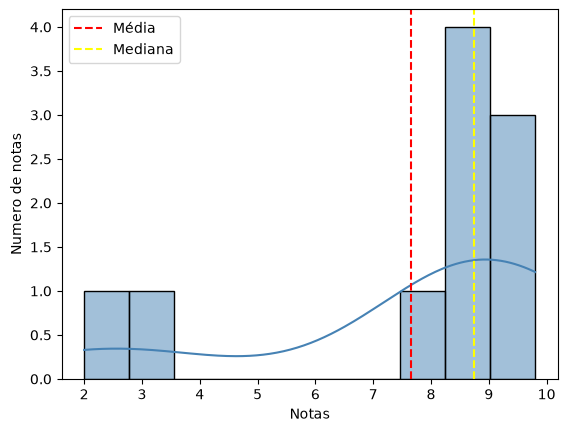

In [38]:
# Escreva aqui o código da Atividade 1 (Nível Básico):
# 1. Transforme a lista em uma `pd.Series`.
notas = pd.Series([2.0, 3.0, 8.0, 8.5, 8.5, 9.0, 9.0, 9.2, 9.5, 9.8])

# 2. Calcule a **Média**, a **Mediana**, a **Assimetria (`.skew()`)** e a **Curtose (`.kurtosis() + 3`)**.
print(f"A media das notas é {notas.mean():.2f}")
print(f"A mediana das notas é {notas.median():.2f}")
print(f"A assimetria das notas é {notas.skew():.2f}")
print(f"A cutose das notas é {(notas.kurtosis() + 3):.2f}")
print('\n' + ('='*80), '\n')

# 3. Consulte as tabelas acima e responda: a turma teve notas simétricas ou assimétricas? A curva é Mesocúrtica, Platicúrtica ou Leptocúrtica?
print("A turma tem notas assimetrica negativamente, team alguns alunos com notas baixas puxado a media pra baixo.")
print("A curva das notas da turma é leptocúrtica, então a notas bem menores e maiores do que a media.")
print('\n' + ('='*80), '\n')

# Grafico
sns.histplot(
    notas,
    bins = 10,
    kde=True,
    #stat="density",
    color="steelblue",
    edgecolor="black",
    )

plt.xlabel("Notas")
plt.ylabel("Numero de notas")
plt.axvline(notas.mean(), color='red', label="Média", linestyle='--')
plt.axvline(notas.median(), color='yellow', label="Mediana", linestyle='--')

plt.legend()
plt.show()

### ATIVIDADE 2  — Reunião da Diretoria (*Data Organized*)
Você vai apresentar os tempos de atendimento (em minutos) de **500 ligações** do suporte técnico:
```python
np.random.seed(10)
ligacoes = np.concatenate([
    np.random.normal(loc=25, scale=4, size=460),   # Ligações rápidas normais
    np.random.uniform(low=55, high=110, size=40)   # Problemas graves demorados
])
```
**Faça:**
1. Calcule **Média, Mediana, Assimetria (`.skew()`) e Curtose (`.kurtosis() + 3`)**.
2. Crie um painel lado a lado (`plt.subplots(1, 2)`) com um **Histograma (`sns.histplot`)** na esquerda (mostrando as linhas da Média e Mediana) e um **Boxplot (`sns.boxplot`)** na direita.
3. Responda como consultor: qual tempo você deve prometer aos clientes como meta padrão (Média ou Mediana) e por quê?

A media dos tempos de atendimento é 29.52
A mediana dos tempos de atendimento é 25.74
A assimetria dos tempos de atendimento é 3.15
A cutose dos tempos de atendimento é 12.45




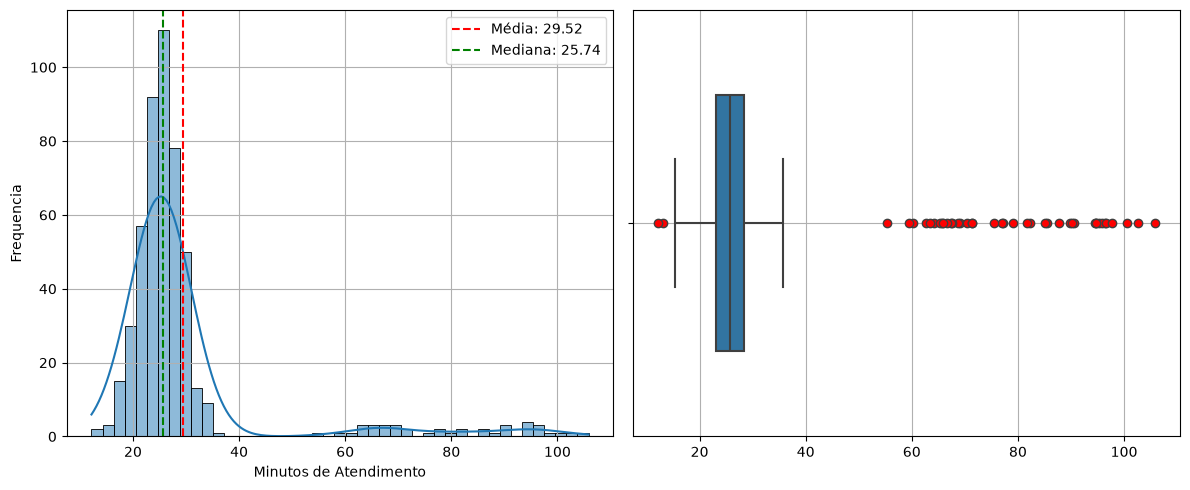

In [ ]:
# Dados da Atividade 2
np.random.seed(10)
ligacoes = np.concatenate([
    np.random.normal(loc=25, scale=4, size=460),
    np.random.uniform(low=55, high=110, size=40)
])

ligacoes = pd.Series(ligacoes)


# Escreva aqui o código da Atividade 2 (Nível Intermediário):
# 1. Calcule **Média, Mediana, Assimetria (`.skew()`) e Curtose (`.kurtosis() + 3`)**.
print(f"A media dos tempos de atendimento é {ligacoes.mean():.2f}")
print(f"A mediana dos tempos de atendimento é {ligacoes.median():.2f}")
print(f"A assimetria dos tempos de atendimento é {ligacoes.skew():.2f}")
print(f"A cutose dos tempos de atendimento é {(ligacoes.kurtosis() + 3):.2f}")
print('\n' + ('='*80), '\n')

# 2. Crie um painel lado a lado (`plt.subplots(1, 2)`) com um **Histograma (`sns.histplot`)** 
# na esquerda (mostrando as linhas da Média e Mediana) e um **Boxplot (`sns.boxplot`)** na direita.

fig, ax = plt.subplots(1,2, figsize=(12, 5))

sns.histplot(
    ligacoes,
    kde=True,
    edgecolor="black",
    ax=ax[0]
)
#plt.grid(axis='y', alpha= .25)

sns.boxplot(
    data=ligacoes,
    ax=ax[1],
    linewidth=1.5,
    width=0.6,
    flierprops={'markerfacecolor': 'red'},
    orient='h'
)

ax[0].grid(True)
ax[0].axvline(ligacoes.mean(), color="red", linestyle='--', label=f'Média: {ligacoes.mean():.2f}')
ax[0].axvline(ligacoes.median(), color="green", linestyle='--', label=f'Mediana: {ligacoes.median():.2f}')
ax[0].set_xlabel(f'Minutos de Atendimento')
ax[0].set_ylabel(f'Frequencia')
ax[0].legend()

ax[1].grid(True)


plt.tight_layout()
plt.show()
# 3. Responda como consultor: qual tempo você deve prometer aos clientes como meta padrão (Média ou Mediana) e por quê?
# 25 - 30 minutos